# Ablations: every ablation study from the checkpoints

**ML4CV project, University of Bologna. Christian Joseph Fiore.**

This notebook re-evaluates all ablation runs from their saved weights (nothing is trained) and rebuilds the ablation tables with the decision rule. Each ablation changes one factor against a fixed baseline. Most settings of the final model were decided by the rule; two were the user's decisions (frame-consistent PE on Cityscapes only, patch mixing kept on). The training of each run is in the development notebooks in `experiments/` (each row names its notebook). Requirements and run time are in the README.

**Protocol:** single pass at the base resolution. Main metrics: NYUv2 RMSE / mIoU, Cityscapes AbsRel (512×1024) / mIoU; also AbsRel, δ1, SwinMTL's per-image mIoU and the log bias (mean log ratio of prediction to GT, > 0 = predicted too far).

**Decision rule** (fixed before the results; `experiments/09_final_model.ipynb`, 'Helpers'): σ = pooled NYUv2 seed std of 3 + 3 seeds, with floors 0.003 m RMSE, 0.2 mIoU, 1 % relative AbsRel; z = Δ / σ (z > 0 = better), |z| ≥ 2.5 is an effect; a change is adopted if one task has z ≥ +2.5 and none has z ≤ −2.5. For Cityscapes σ is transferred from NYUv2; the measured Cityscapes AbsRel seed std (≈ 2 %) is about twice the floor, so the Cityscapes depth z-scores are about 2× too large.

Results go to `results/reproduce/ablations/`, cached (`FORCE = True` recomputes).

In [1]:
FORCE = False      # recompute the evaluations even if cached in results/reproduce/ablations
LOG_BIAS = True    # also the log bias of every run with a depth head (one extra pass per run)
RES = True         # inference-resolution study ('Inference resolution'): 3 models x 6 input scales

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [2]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [3]:
from repro_common import *

setup()
OUT = REPRO_DIR / "ablations"
OUT.mkdir(parents=True, exist_ok=True)
print(f"Device: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU'}), output: {OUT}")

Device: cuda (NVIDIA RTX A4000), output: /home/chrisjf/Documents/ml4cv/results/reproduce/ablations


## The runs
Every checkpoint used by the ablations: an id, the run folder under `ckpt/`, the dataset, the settings that matter at test time, and the notebook that trained it.
- `frame_pe`: frame-consistent position embeddings.
- `depth_param`: linear or log-space depth output.
- `depth_head`: the regression head, or DINOv2's 256-bin head (D4).

Settings used only in training (critic, augmentations, loss weights, seed) do not change the evaluation.

In [4]:
FPE = dict(frame_pe=True)
RUNS = {
    # id: (run folder under ckpt/, dataset, test-time settings, trained in)
    # notebook 02: baseline recipe (critic on), A = frozen backbone, B = last 4 blocks fine-tuned
    "CS-A":  ("cityscapes_frozen", "cityscapes", {}, "02"),
    "CS-B":  ("cityscapes_partial_ft", "cityscapes", {}, "02"),
    "NYU-A": ("nyu_frozen", "nyu", {}, "02"),
    "NYU-B": ("nyu_partial_ft", "nyu", {}, "02"),
    # notebook 04: E1 = 8 blocks, E2 = B without critic
    "E1": ("exp/nyu_partial_ft8", "nyu", {}, "04"),
    "E2": ("nocritic/nyu_partial_ft", "nyu", {}, "04"),
    # notebook 05: AB1 = B + frame-consistent position embeddings
    "AB1": ("fpe/cityscapes_partial_ft", "cityscapes", FPE, "05"),
    # notebook 06: seed repeats without critic, 4 blocks (seed 42 = E2) and 8 blocks
    "NC4-s43": ("seeds/nc4_s43/nyu_partial_ft", "nyu", {}, "06"),
    "NC4-s44": ("seeds/nc4_s44/nyu_partial_ft", "nyu", {}, "06"),
    **{f"NC8-s{s}": (f"seeds/nc8_s{s}/nyu_partial_ft8", "nyu", {}, "06") for s in (42, 43, 44)},
    # notebook 07: augmentation ablations on 8 blocks (baseline NC8-s42), AUG-A also on 4 blocks
    **{f"AUG-{x.upper()}": (f"aug/aug_{x}/nyu_partial_ft8", "nyu", {}, "07") for x in "abcd"},
    "AUG-A-4blk": ("aug_4blk/aug_a/nyu_partial_ft", "nyu", {}, "07"),
    # notebook 09: configuration chosen by the rule (frame PE on both datasets), seed 42, and the LOG ablation
    "CS-F9":    ("final/cityscapes_base_s42/cityscapes_final", "cityscapes", FPE, "09"),
    "CS-LOG":   ("final/cityscapes_log_s42/cityscapes_final", "cityscapes", dict(FPE, depth_param="log"), "09"),
    "NYU-F9":   ("final/nyu_base_s42/nyu_final", "nyu", FPE, "09"),
    "NYU-LOG":  ("final/nyu_log_s42/nyu_final", "nyu", dict(FPE, depth_param="log"), "09"),
    # notebook 10 ('Runs'): ablations on the notebook 09 configuration
    "NYU-noFPE":    ("final/nyu_base-noframepe_s42/nyu_final", "nyu", {}, "10"),
    "CS-depthonly": ("final/cityscapes_base-depthonly_s42/cityscapes_final", "cityscapes", FPE, "10"),
    "CS-segonly":   ("final/cityscapes_base-segonly_s42/cityscapes_final", "cityscapes", FPE, "10"),
    "NYU-F9-depthonly": ("final/nyu_base-depthonly_s42/nyu_final", "nyu", FPE, "10"),
    "NYU-F9-segonly":   ("final/nyu_base-segonly_s42/nyu_final", "nyu", FPE, "10"),
    "NYU-F9-noPM":      ("final/nyu_base-nopatchmix_s42/nyu_final", "nyu", FPE, "10"),
    "NYU-F9-bins":      ("final/nyu_base-bins_s42/nyu_final", "nyu", dict(FPE, depth_head="bins"), "10"),
    # notebook 10 ('NYU ablations re-based on the NYU final model'): ablations on the NYU final model (= NC8, standard position embeddings)
    "NYU-depthonly": ("final/nyu_base-nofpe-depthonly_s42/nyu_final", "nyu", {}, "10"),
    "NYU-segonly":   ("final/nyu_base-nofpe-segonly_s42/nyu_final", "nyu", {}, "10"),
    # notebook 12: NYU final model with patch mixing off, 3 seeds (not adopted; seed 42 trained in notebook 10)
    **{f"NYU-noPM-s{s}": (f"final/nyu_base-nofpe-nopatchmix_s{s}/nyu_final", "nyu", {}, "12") for s in (42, 43, 44)},
    # notebook 13: single-task on the patch-mixing-off configuration (supplementary)
    "NYU-noPM-depthonly": ("final/nyu_base-nopm-depthonly_s42/nyu_final", "nyu", {}, "13"),
    "NYU-noPM-segonly":   ("final/nyu_base-nopm-segonly_s42/nyu_final", "nyu", {}, "13"),
    # notebook 11: D1 = DINOv2's depth setup (frozen ViT-S + DPT, depth only) on the 795 NYU images
    "D1": ("d1/nyu_frozen", "nyu", {}, "11"),
}
SEG_ONLY = {"CS-segonly", "NYU-F9-segonly", "NYU-segonly", "NYU-noPM-segonly"}   # no trained depth head
DEPTH_ONLY = {"CS-depthonly", "NYU-F9-depthonly", "NYU-depthonly", "NYU-noPM-depthonly", "D1"}
missing = [k for k, (run, *_) in RUNS.items() if not (ROOT / "ckpt" / run / "final.pt").exists()]
print(f"{len(RUNS)} runs, missing checkpoints: {missing or 'none'}")
assert not missing

36 runs, missing checkpoints: none


## Evaluation of every run

In [5]:
EVAL = {}
for rid, (run, dataset, settings, nb) in RUNS.items():
    def compute():
        model = load_run(run, dataset, **settings)
        r = eval_cityscapes(model) if dataset == "cityscapes" else eval_nyu(model)
        if LOG_BIAS and rid not in SEG_ONLY:
            r["log_bias"] = log_bias(model, dataset)
        del model
        torch.cuda.empty_cache()
        return r
    EVAL[rid] = cached(OUT / f"{rid}.json", compute, FORCE)
    d, s = main_metrics(dataset, EVAL[rid])
    print(f"{rid:20s} ({dataset:10s}, nb {nb}): depth {d:.4f}  mIoU {s:.2f}" + (f"  log bias {EVAL[rid]['log_bias']:+.4f}" if "log_bias" in EVAL[rid] else ""))

CS-A                 (cityscapes, nb 02): depth 0.1259  mIoU 74.99  log bias +0.0675
CS-B                 (cityscapes, nb 02): depth 0.1221  mIoU 77.26  log bias +0.0747
NYU-A                (nyu       , nb 02): depth 0.4671  mIoU 53.88  log bias +0.0330
NYU-B                (nyu       , nb 02): depth 0.4329  mIoU 57.27  log bias +0.0237
E1                   (nyu       , nb 04): depth 0.4242  mIoU 57.79  log bias +0.0177
E2                   (nyu       , nb 04): depth 0.4282  mIoU 57.39  log bias +0.0151
AB1                  (cityscapes, nb 05): depth 0.1077  mIoU 76.99  log bias +0.0522
NC4-s43              (nyu       , nb 06): depth 0.4320  mIoU 57.41  log bias +0.0147
NC4-s44              (nyu       , nb 06): depth 0.4290  mIoU 57.37  log bias +0.0190
NC8-s42              (nyu       , nb 06): depth 0.4205  mIoU 58.25  log bias +0.0208
NC8-s43              (nyu       , nb 06): depth 0.4205  mIoU 58.16  log bias +0.0172
NC8-s44              (nyu       , nb 06): depth 0.4183  mIoU 57.8

## Seed noise σ (notebook 06)
- **4 blocks:** E2 (seed 42), NC4-s43, NC4-s44.
- **8 blocks:** NC8-s42–44.

Both arms are trained without the critic, with 3 seeds each. The pooled std, with the floors, is the σ of the decision rule.

In [6]:
ARMS = {"4 blocks": [EVAL[k] for k in ("E2", "NC4-s43", "NC4-s44")], "8 blocks": [EVAL[f"NC8-s{s}"] for s in (42, 43, 44)]}
SIGMA = seed_sigma(ARMS)
print("measured (raw):", {k: round(v, 5) for k, v in SIGMA["raw"].items()})
print("used (floors applied):", {k: SIGMA[k] for k in ("rmse", "miou", "abs_rel_cv")})


def mean_eval(ids):
    """Mean of the main metrics over several seeds, as an evaluation dict."""
    rs = [EVAL[i] for i in ids]
    if "nyu_depth" in rs[0]:
        return {"nyu_depth": {"rmse": np.mean([r["nyu_depth"]["rmse"] for r in rs])}, "nyu_seg": {"mIoU": np.mean([r["nyu_seg"]["mIoU"] for r in rs])}}
    return {"cs_depth_512x1024": {"abs_rel": np.mean([r["cs_depth_512x1024"]["abs_rel"] for r in rs])}, "cs_seg": {"mIoU": np.mean([r["cs_seg"]["mIoU"] for r in rs])}}

measured (raw): {'rmse': 0.00167, 'miou': 0.13891, 'abs_rel_cv': np.float64(0.006)}
used (floors applied): {'rmse': 0.003, 'miou': 0.2, 'abs_rel_cv': 0.01}


## All ablations
One row per ablation: baseline → change, main metrics, z-scores and the decision taken in the project.
- Multi-seed rows (E1-seeds, PM 3 seeds) compare the means of 3 + 3 seeds.
- Single-task rows compare only the trained task.
- **Superseded** rows were measured against the notebook 09 NYU configuration, which has frame PE on. After the user's option A (frame PE on Cityscapes only), they were repeated against the NYU final model in the rows below them.

In [7]:
ABLATIONS = [
    # (id, change, dataset, baseline ids, ablation ids, decision)
    ("A/B", "frozen backbone -> last 4 blocks fine-tuned", "cityscapes", ["CS-A"], ["CS-B"], "fine-tune"),
    ("A/B", "frozen backbone -> last 4 blocks fine-tuned", "nyu", ["NYU-A"], ["NYU-B"], "fine-tune"),
    ("E1", "4 -> 8 fine-tuned blocks (critic on, 1 seed)", "nyu", ["NYU-B"], ["E1"], "see E1-seeds"),
    ("E1-seeds", "4 -> 8 fine-tuned blocks (critic off, 3 + 3 seeds)", "nyu", ["E2", "NC4-s43", "NC4-s44"], ["NC8-s42", "NC8-s43", "NC8-s44"], "8 blocks"),
    ("E2", "WGAN-GP critic on -> off", "nyu", ["NYU-B"], ["E2"], "critic off (no effect, 1.8x faster training)"),
    ("AB1", "standard -> frame-consistent position embeddings", "cityscapes", ["CS-B"], ["AB1"], "on for Cityscapes"),
    ("AUG-A", "rescale [1, 1.5] + crop 476x630 -> no rescale + crop 448x574", "nyu", ["NC8-s42"], ["AUG-A"], "keep rescale [1, 1.5]"),
    ("AUG-A (4 blocks)", "same as AUG-A, on 4 blocks (interaction check)", "nyu", ["E2"], ["AUG-A-4blk"], "not used for the decision"),
    ("AUG-B", "rescale [1, 1.5] -> [0.5, 2.0]", "nyu", ["NC8-s42"], ["AUG-B"], "unchanged (below threshold)"),
    ("AUG-C", "+ rotation +-2.5 deg", "nyu", ["NC8-s42"], ["AUG-C"], "no rotation"),
    ("AUG-D", "photometric RNG shared by data-loader workers -> seeded per worker (bug fix)", "nyu", ["NC8-s42"], ["AUG-D"], "fix adopted (neutral)"),
    ("LOG", "linear -> log-space depth output", "nyu", ["NYU-F9"], ["NYU-LOG"], "linear"),
    ("LOG", "linear -> log-space depth output", "cityscapes", ["CS-F9"], ["CS-LOG"], "linear"),
    ("FPE-NYU", "frame-consistent position embeddings on -> off", "nyu", ["NYU-F9"], ["NYU-noFPE"], "off on NYU (user, option A)"),
    ("ST-D", "multi-task -> depth only", "cityscapes", ["CS-F9"], ["CS-depthonly"], "stays multi-task (cost of multi-task learning)"),
    ("ST-S", "multi-task -> segmentation only", "cityscapes", ["CS-F9"], ["CS-segonly"], "stays multi-task"),
    ("ST-D (superseded)", "multi-task -> depth only, vs notebook 09 NYU config", "nyu", ["NYU-F9"], ["NYU-F9-depthonly"], "superseded"),
    ("ST-S (superseded)", "multi-task -> segmentation only, vs notebook 09 NYU config", "nyu", ["NYU-F9"], ["NYU-F9-segonly"], "superseded"),
    ("PM (superseded)", "patch mixing on -> off, vs notebook 09 NYU config", "nyu", ["NYU-F9"], ["NYU-F9-noPM"], "superseded"),
    ("D4", "sigmoid output -> DINOv2 256-bin head (side ablation)", "nyu", ["NYU-F9"], ["NYU-F9-bins"], "side ablation only"),
    ("ST-D", "multi-task -> depth only", "nyu", ["NC8-s42"], ["NYU-depthonly"], "stays multi-task (cost of multi-task learning)"),
    ("ST-S", "multi-task -> segmentation only", "nyu", ["NC8-s42"], ["NYU-segonly"], "stays multi-task"),
    ("PM", "patch mixing on -> off (3 + 3 seeds)", "nyu", ["NC8-s42", "NC8-s43", "NC8-s44"], ["NYU-noPM-s42", "NYU-noPM-s43", "NYU-noPM-s44"],
     "kept on: per-image mIoU vs SwinMTL drops (see 'Details of the decision-driving ablations')"),
    ("ST-D (no PM, suppl.)", "multi-task -> depth only, on the patch-mixing-off config", "nyu", ["NYU-noPM-s42"], ["NYU-noPM-depthonly"], "supplementary"),
    ("ST-S (no PM, suppl.)", "multi-task -> segmentation only, on the patch-mixing-off config", "nyu", ["NYU-noPM-s42"], ["NYU-noPM-segonly"], "supplementary"),
]
rows = []
for aid, change, dataset, base, new, decision in ABLATIONS:
    j = judge(dataset, mean_eval(base), mean_eval(new), SIGMA)
    if any(i in SEG_ONLY for i in new):
        j.update(depth_base=None, depth_new=None, z_depth=None)
    if any(i in DEPTH_ONLY for i in new):
        j.update(mIoU_base=None, mIoU_new=None, z_seg=None)
    rows.append(dict(id=aid, change=change, dataset=dataset, **j, decision=decision))
ALL = pd.DataFrame(rows)
ALL.to_csv(OUT / "all_ablations.csv", index=False)


def zcolor(v):
    if v is None or pd.isna(v):
        return ""
    return "background-color: rgba(0,180,0,.25)" if v >= Z else ("background-color: rgba(220,0,0,.2)" if v <= -Z else "")


display(ALL.style.format(precision=4, na_rep="—").map(zcolor, subset=["z_depth", "z_seg"]))
print(f"depth metric: NYU RMSE (m), Cityscapes AbsRel; green / red = |z| >= {Z}")

,id,change,dataset,depth_base,depth_new,z_depth,mIoU_base,mIoU_new,z_seg,decision
0,A/B,frozen backbone -> last 4 blocks fine-tuned,cityscapes,0.1259,0.1221,3.0143,74.9901,77.2636,11.3671,fine-tune
1,A/B,frozen backbone -> last 4 blocks fine-tuned,nyu,0.4671,0.4329,11.4020,53.8816,57.2734,16.9588,fine-tune
2,E1,"4 -> 8 fine-tuned blocks (critic on, 1 seed)",nyu,0.4329,0.4242,2.8812,57.2734,57.7933,2.5994,see E1-seeds
3,E1-seeds,"4 -> 8 fine-tuned blocks (critic off, 3 + 3 seeds)",nyu,0.4297,0.4197,3.3242,57.3909,58.0957,3.5240,8 blocks
4,E2,WGAN-GP critic on -> off,nyu,0.4329,0.4282,1.5524,57.2734,57.3912,0.5889,"critic off (no effect, 1.8x faster training)"
5,AB1,standard -> frame-consistent position embeddings,cityscapes,0.1221,0.1077,11.7867,77.2636,76.9943,-1.3464,on for Cityscapes
6,AUG-A,"rescale [1, 1.5] + crop 476x630 -> no rescale + crop 448x574",nyu,0.4205,0.4365,-5.3418,58.2490,56.4518,-8.9861,"keep rescale [1, 1.5]"
7,AUG-A (4 blocks),"same as AUG-A, on 4 blocks (interaction check)",nyu,0.4282,0.4463,-6.0360,57.3912,55.8699,-7.6064,not used for the decision
8,AUG-B,"rescale [1, 1.5] -> [0.5, 2.0]",nyu,0.4205,0.4244,-1.2934,58.2490,58.6394,1.9516,unchanged (below threshold)
9,AUG-C,+ rotation +-2.5 deg,nyu,0.4205,0.4183,0.7300,58.2490,58.1729,-0.3808,no rotation


depth metric: NYU RMSE (m), Cityscapes AbsRel; green / red = |z| >= 2.5


## Details of the decision-driving ablations
Secondary metrics for the rows where the main metrics do not tell the whole story:
- **AB1:** frame PE changes the global depth scale (log bias), not the structure.
- **PM:** the depth gain is clear, but my per-image mIoU (SwinMTL's metric) drops below SwinMTL's 58.14. This is why patch mixing was kept.
- **ST-D:** depth-only training.
- **D1:** DINOv2's own depth setup on my 795 images.

In [8]:
def detail(rid):
    r = EVAL[rid]
    d = r.get("nyu_depth") or r.get("cs_depth_512x1024")
    s = r.get("nyu_seg") or r.get("cs_seg")
    p = r.get("nyu_seg_swinmtl") or r.get("cs_seg_swinmtl")
    return dict(run=rid, RMSE=d["rmse"], AbsRel=d["abs_rel"], d1=d["d1"], mIoU=s["mIoU"], mIoU_per_image=p["mIoU"], log_bias=r.get("log_bias"))


print("AB1 (Cityscapes): frame-consistent position embeddings")
display(pd.DataFrame([detail(k) for k in ("CS-B", "AB1", "CS-F9")]).set_index("run").style.format(precision=4))

print("PM (NYUv2): patch mixing on (NC8 = final model) vs off, per seed, then mean +- std")
pm_rows = [dict(detail(k), arm=arm) for arm, ks in [("on", [f"NC8-s{s}" for s in (42, 43, 44)]), ("off", [f"NYU-noPM-s{s}" for s in (42, 43, 44)])] for k in ks]
pm_df = pd.DataFrame(pm_rows)
display(pm_df.set_index("run").style.format(precision=4))
summary = pm_df.groupby("arm")[["RMSE", "AbsRel", "d1", "mIoU", "mIoU_per_image", "log_bias"]].agg(["mean", "std"])
display(summary.style.format(precision=4))
on, off = pm_df[pm_df.arm == "on"], pm_df[pm_df.arm == "off"]
for col in ("RMSE", "mIoU", "mIoU_per_image"):
    print(f"  {col:15s} on {on[col].mean():.4f} -> off {off[col].mean():.4f}"
          + (f"; seeds above SwinMTL's {PAPER["swinmtl_tab3"]["SwinMTL"][1]}: on {int((on[col] > PAPER["swinmtl_tab3"]["SwinMTL"][1]).sum())}/3, off {int((off[col] > PAPER["swinmtl_tab3"]["SwinMTL"][1]).sum())}/3" if col == "mIoU_per_image" else ""))

print(f"ST-D (NYUv2) and D1: depth-only models vs the multi-task final model (seed 42); DINOv2 + DPT reports {PAPER["dinov2_tab11_vits14"]["nyu"][2]} with ~24k frames")
display(pd.DataFrame([detail(k) for k in ("NC8-s42", "NYU-depthonly", "NYU-noPM-depthonly", "D1")]).set_index("run")
        .drop(columns=["mIoU", "mIoU_per_image"]).style.format(precision=4, na_rep="—"))

AB1 (Cityscapes): frame-consistent position embeddings


,RMSE,AbsRel,d1,mIoU,mIoU_per_image,log_bias
run,,,,,,
CS-B,5.4227,0.1221,0.8968,77.2636,64.5593,0.0747
AB1,5.1843,0.1077,0.9062,76.9943,64.4405,0.0522
CS-F9,5.0462,0.1059,0.9136,77.9468,65.2078,0.0574


PM (NYUv2): patch mixing on (NC8 = final model) vs off, per seed, then mean +- std


,RMSE,AbsRel,d1,mIoU,mIoU_per_image,log_bias,arm
run,,,,,,,
NC8-s42,0.4205,0.1215,0.8637,58.2490,58.5486,0.0208,on
NC8-s43,0.4205,0.1198,0.8663,58.1626,58.5634,0.0172,on
NC8-s44,0.4183,0.1199,0.8656,57.8754,58.1777,0.0204,on
NYU-noPM-s42,0.4021,0.1150,0.8798,58.5685,57.6325,0.0227,off
NYU-noPM-s43,0.4041,0.1145,0.8807,58.6966,57.9478,0.0192,off
NYU-noPM-s44,0.4046,0.1153,0.8792,57.5341,57.2686,0.0186,off


  RMSE            on 0.4197 -> off 0.4036
  mIoU            on 58.0957 -> off 58.2664
  mIoU_per_image  on 58.4299 -> off 57.6163; seeds above SwinMTL's 58.14: on 3/3, off 0/3
ST-D (NYUv2) and D1: depth-only models vs the multi-task final model (seed 42); DINOv2 + DPT reports 0.356 with ~24k frames


,RMSE,AbsRel,d1,log_bias
run,,,,
NC8-s42,0.4205,0.1215,0.8637,0.0208
NYU-depthonly,0.3834,0.1090,0.8915,0.0145
NYU-noPM-depthonly,0.3787,0.1064,0.8953,0.0174
D1,0.4199,0.1227,0.8629,0.0231


## Inference resolution (RES, evaluation only; notebook 08)
- The input is resized by s and the predictions are evaluated at the standard resolution.
- The **metric depth scale depends on the input size** for this ViT (log bias). Segmentation changes much less: within about ±1 mIoU for s ∈ [0.875, 1.5], about −3 at s = 0.75 on Cityscapes.
- s = 1 stays the protocol: picking another s would be tuning on the test set.

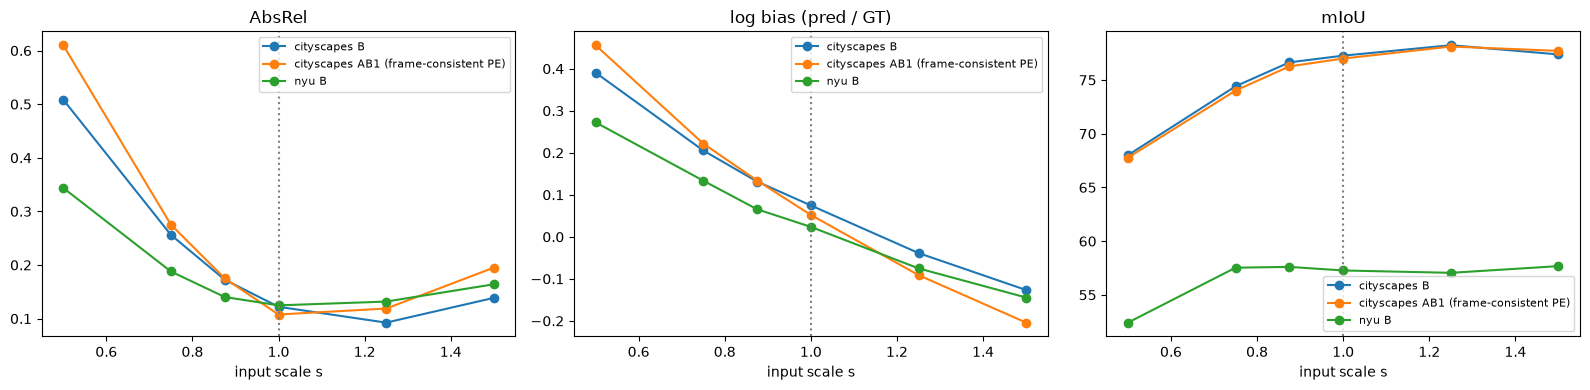

In [9]:
if RES:
    SCALES = [0.5, 0.75, 0.875, 1.0, 1.25, 1.5]
    def compute_res():
        out = []
        for rid, label in [("CS-B", "B"), ("AB1", "AB1 (frame-consistent PE)"), ("NYU-B", "B")]:
            run, dataset, settings, _ = RUNS[rid]
            model = load_run(run, dataset, **settings)
            for s in SCALES:
                out.append(dict(dataset=dataset, model=label, scale=s, **eval_resolution(model, dataset, s)))
            del model
            torch.cuda.empty_cache()
        return out
    res = pd.DataFrame(cached(OUT / "inference_resolution.json", compute_res, FORCE))
    res.to_csv(OUT / "inference_resolution.csv", index=False)
    display(res.set_index(["dataset", "model", "scale"]).style.format(precision=4))

    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    for (dataset, label), g in res.groupby(["dataset", "model"], sort=False):
        for ax, col in zip(axs, ["abs_rel", "log_bias", "mIoU"]):
            ax.plot(g["scale"], g[col], "o-", label=f"{dataset} {label}")
    for ax, title in zip(axs, ["AbsRel", "log bias (pred / GT)", "mIoU"]):
        ax.axvline(1.0, color="gray", ls=":"); ax.set_title(title); ax.set_xlabel("input scale s"); ax.legend(fontsize=8)
    plt.tight_layout()
    fig.savefig(OUT / "inference_resolution.png", dpi=120)
    plt.show()

## Reproduction check
Each reproduced evaluation is compared with the original one, saved by the development notebooks in `results/` (skipped if that folder is not present).
- The table gives the number of metrics compared and the largest relative difference per run.
- The table of all ablations is also compared with the original `results/compare/all_ablations.csv`.
- On another GPU, floating-point differences of about 1e-4 relative are expected.

In [10]:
rows = []
for rid, (run, dataset, settings, nb) in RUNS.items():
    c = compare_with_original(EVAL[rid], load_json(original_eval_path(run)))
    rows.append(dict(run=rid, notebook=nb, **(c or dict(n_metrics=0, max_rel_diff=None, worst="original not found"))))
check = pd.DataFrame(rows)
check.to_csv(OUT / "reproduction_check.csv", index=False)
display(check)
if check["max_rel_diff"].notna().any():
    print(f"largest relative difference over all runs: {check['max_rel_diff'].max():.2e}")

orig_path = ROOT / "results" / "compare" / "all_ablations.csv"
if orig_path.exists():
    orig = pd.read_csv(orig_path)
    diffs = []
    for col in ("depth_base", "depth_new", "mIoU_base", "mIoU_new"):
        o = orig[col].dropna().round(6).tolist()
        n = ALL[col].dropna().astype(float).round(6).tolist()
        diffs.append(dict(column=col, original_values=len(o), reproduced_values=len(n),
                          reproduced_found_in_original=sum(any(abs(v - w) <= 1e-4 * max(abs(w), 1e-9) for w in o) for v in n)))
    print("all_ablations.csv: reproduced main metrics that match a value of the original table (relative tolerance 1e-4)")
    display(pd.DataFrame(diffs))

,run,notebook,n_metrics,max_rel_diff,worst,new,original
0,CS-A,02,22,0.0,cs_depth_512x1024.d1,0.883328,0.883328
1,CS-B,02,22,0.0,cs_depth_512x1024.d1,0.896750,0.896750
2,NYU-A,02,22,0.0,nyu_depth.d1,0.832295,0.832295
3,NYU-B,02,22,0.0,nyu_depth.d1,0.856984,0.856984
4,E1,04,22,0.0,nyu_depth.d1,0.862270,0.862270
5,E2,04,23,0.0,nyu_depth.d1,0.860120,0.860120
6,AB1,05,23,0.0,cs_depth_512x1024.d1,0.906200,0.906200
7,NC4-s43,06,22,0.0,nyu_depth.d1,0.860271,0.860271
8,NC4-s44,06,22,0.0,nyu_depth.d1,0.860467,0.860467
9,NC8-s42,06,23,0.0,nyu_depth.d1,0.863679,0.863679


largest relative difference over all runs: 0.00e+00
all_ablations.csv: reproduced main metrics that match a value of the original table (relative tolerance 1e-4)


,column,original_values,reproduced_values,reproduced_found_in_original
0,depth_base,20,21,19
1,depth_new,20,21,19
2,mIoU_base,20,21,19
3,mIoU_new,20,21,19
